# 04 · Eleição do vencedor e promoção controlada

**Etapa 5.**
1. O vencedor do ciclo é o candidato de **menor MAE** na validação temporal.
2. **Sem modelo vigente** (`models/modelo_vigente.json` inexistente) → promoção direta.
3. **Com vigente** → o vigente (carregado do armazenamento persistente do repositório, com verificação de hash) é avaliado **na mesma validação** do ciclo atual, com as **suas próprias** features e pré-processamento. O desafiante só é promovido se
   `MAE_vigente − MAE_desafiante ≥ promotion_threshold` (0,5 bicicleta/hora, `config.yaml`).
4. Caso contrário o vigente é **mantido**. Modelos promovidos ficam preservados em `models/registro/`.

Como os modelos são treinados apenas na parte de treino de cada ciclo, a validação do ciclo atual é **inédita para os dois** – comparação justa e sem vazamento.

Também aqui: **explicabilidade SHAP** do vencedor do ciclo (Critério 10).

In [1]:
# Setup: garante caminhos consistentes (nbconvert executa com cwd = notebooks/)
import os, sys, warnings
from pathlib import Path

RAIZ = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "config" / "config.yaml").exists())
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
warnings.filterwarnings("ignore")

import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
import mlflow

from src import utils
cfg = utils.carregar_config()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
print("Raiz do projeto:", RAIZ)

Raiz do projeto: /home/runner/work/bsd/bsd


In [2]:
import joblib
from src import preprocessamento as pp, modelagem, promocao, ingestao, monitoramento

ciclo = utils.carregar_ciclo()
DIR_EV = utils.dir_evidencias(ciclo["cycle_id"])
comp = utils.ler_json(utils.DIR_PROCESSED / "resultado_competicao.json")
assert comp["cycle_id"] == ciclo["cycle_id"], "Competição não pertence ao ciclo atual"
assert len(comp["resultados"]) == 2, "Os dois algoritmos devem ter sido treinados"

metrica, direcao = cfg["metrica"]["principal"], cfg["metrica"]["direcao"]
limiar = cfg["promocao"]["promotion_threshold"]

vencedor = promocao.eleger_vencedor(comp["resultados"], metrica, direcao)
display(pd.DataFrame([{"algoritmo": r["algoritmo"], f"val_{metrica}": r["metricas"][f"val_{metrica}"],
                       "vencedor_do_ciclo": r is vencedor} for r in comp["resultados"]]))
print("Vencedor do ciclo:", vencedor["algoritmo"])

,algoritmo,val_mae,vencedor_do_ciclo
0,Ridge,109.710560,False
1,RandomForestRegressor,51.623846,True


Vencedor do ciclo: RandomForestRegressor


## Confronto com o modelo vigente (mesma validação)

In [3]:
dados = pd.read_parquet(utils.DIR_PROCESSED / "dataset_ciclo.parquet")
_, val = pp.separar_treino_validacao(dados, cfg)
y_val = val[cfg["dados"]["alvo"]].astype(float)

# Reavalia o desafiante a partir do artefato serializado (garante que é o mesmo objeto que será promovido)
desafiante = joblib.load(utils.RAIZ / vencedor["arquivo_candidato"])
valor_desafiante = modelagem.avaliar(y_val, desafiante.predict(val))[metrica]
assert abs(valor_desafiante - vencedor["metricas"][f"val_{metrica}"]) < 1e-6

manifesto_antigo = promocao.carregar_manifesto()
valor_vigente, metricas_vigente = None, None
if manifesto_antigo:
    vigente = promocao.carregar_modelo_vigente(manifesto_antigo)
    metricas_vigente = modelagem.avaliar(y_val, vigente.predict(val))
    valor_vigente = metricas_vigente[metrica]
    print(f"Vigente: {manifesto_antigo['modelo_id']} (dados {manifesto_antigo['data_version']}) "
          f"-> {metrica.upper()} na validação do {ciclo['cycle_id']} = {valor_vigente:.4f}")
else:
    print("Nenhum modelo vigente encontrado: primeiro ciclo.")

decisao = promocao.decidir(valor_desafiante, valor_vigente, limiar, direcao)
print(f"\nDesafiante {vencedor['algoritmo']} -> {metrica.upper()} = {valor_desafiante:.4f}")
print(f"DECISÃO: {decisao['decisao']} — {decisao['motivo']}")

Vigente: ciclo_2__RandomForestRegressor (dados v2) -> MAE na validação do ciclo_6 = 51.6238

Desafiante RandomForestRegressor -> MAE = 51.6238
DECISÃO: MANTIDO — Melhoria de -0.0000 < limiar 0.5 (vigente=51.6238, desafiante=51.6238).


## Explicabilidade SHAP do vencedor do ciclo (Critério 10)

,feature,shap_media_absoluta
0,hr,86.591398
1,yr,49.029861
2,is_rush_hour,45.905517
3,atemp,25.677549
4,temp,23.906242
5,workingday,22.195071
6,hr_sin,18.245099
7,hr_cos,17.365972
8,hum,11.346507
9,weathersit,6.509740


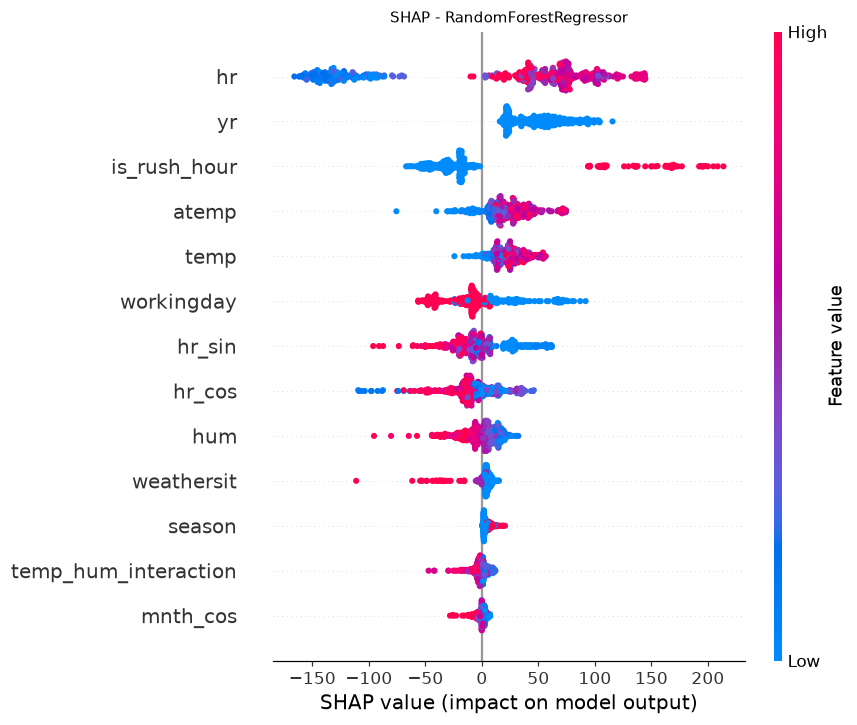

In [4]:
shap_png = DIR_EV / "shap_summary_vencedor.png"
shap_imp = monitoramento.explicar_shap(desafiante, val, vencedor["features"], cfg, shap_png)
shap_imp.to_csv(DIR_EV / "shap_importancia_vencedor.csv", index=False)
display(shap_imp)
display(Image(shap_png))

## Registro da decisão (MLflow + manifesto + estado do pipeline)

In [5]:
exp_id = utils.configurar_mlflow(cfg)
nome_registro = cfg["projeto"]["nome"]
with mlflow.start_run(run_name=f"{ciclo['cycle_id']}_04_decisao",
                      tags={**utils.tags_ciclo(ciclo, "04_decisao"), "decisao": decisao["decisao"]}) as run:
    mlflow.log_params({
        "cycle_id": ciclo["cycle_id"], "data_version": ciclo["data_version"],
        "vencedor_ciclo": vencedor["algoritmo"], "run_id_vencedor": vencedor["run_id"],
        "metrica": metrica, "direcao": direcao, "promotion_threshold": limiar,
        "vigente_anterior": manifesto_antigo["modelo_id"] if manifesto_antigo else "nenhum",
        "decisao": decisao["decisao"], "motivo": decisao["motivo"][:500],
        "features_vencedor": ",".join(vencedor["features"]),
    })
    mlflow.log_metric(f"desafiante_val_{metrica}", valor_desafiante)
    if valor_vigente is not None:
        mlflow.log_metric(f"vigente_val_{metrica}", valor_vigente)
        mlflow.log_metric("melhoria", decisao["melhoria"])
    mlflow.log_metric("promovido", int(decisao["promover"]))
    for r in comp["resultados"]:
        mlflow.log_metric(f"{r['algoritmo']}_val_{metrica}", r["metricas"][f"val_{metrica}"])
    mlflow.log_artifact(str(shap_png), "shap")
    mlflow.log_artifact(str(DIR_EV / "shap_importancia_vencedor.csv"), "shap")
    run_id_decisao = run.info.run_id

arquivo_modelo = None
if decisao["promover"]:
    arquivo_modelo = promocao.arquivar_modelo(utils.RAIZ / vencedor["arquivo_candidato"],
                                              ciclo["cycle_id"], vencedor["algoritmo"])
    # Model Registry do MLflow: nova versão com alias "vigente"
    mv = mlflow.register_model(vencedor["model_uri"], nome_registro,
                               tags={"cycle_id": ciclo["cycle_id"], "data_version": ciclo["data_version"]})
    mlflow.MlflowClient().set_registered_model_alias(nome_registro, "vigente", mv.version)
    print(f"Registrado no Model Registry: {nome_registro} v{mv.version} (alias 'vigente')")

manifesto = promocao.atualizar_manifesto(manifesto_antigo, vencedor, ciclo, decisao, metrica, direcao,
                                         run_id_decisao, arquivo_modelo, valor_vigente,
                                         cfg["projeto"]["experimento_mlflow"])
with mlflow.start_run(run_id=run_id_decisao):
    mlflow.log_dict(manifesto, "manifesto/modelo_vigente.json")

registro_decisao = {**manifesto["historico_decisoes"][-1], "manifesto_vigente": manifesto["modelo_id"],
                    "metricas_vigente_anterior": metricas_vigente}
utils.salvar_json(registro_decisao, DIR_EV / "decisao_promocao.json")

# Estado persistente do pipeline: só é atualizado se todo o ciclo chegou até aqui
estado = ingestao.carregar_estado()
estado["execucoes"] = ciclo["numero_execucao"]
estado["lotes_incorporados"] = ciclo["lotes_ciclo"]
estado["historico"].append({"cycle_id": ciclo["cycle_id"], "data_version": ciclo["data_version"],
                            "lote_novo": ciclo["lote_novo"], "decisao": decisao["decisao"],
                            "vencedor_ciclo": vencedor["algoritmo"], "modelo_vigente": manifesto["modelo_id"],
                            "gatilho": ciclo["gatilho"], "github_run_id": ciclo["github_run_id"],
                            "concluido_em": utils.agora_iso()})
ingestao.salvar_estado(estado)
print(json.dumps({k: manifesto[k] for k in ["modelo_id", "algoritmo", "data_version", "features", "metrica", "mlflow", "arquivo_modelo"]},
                 indent=2, ensure_ascii=False))

{
  "modelo_id": "ciclo_2__RandomForestRegressor",
  "algoritmo": "RandomForestRegressor",
  "data_version": "v2",
  "features": [
    "is_rush_hour",
    "hr_sin",
    "atemp",
    "temp",
    "hr_cos",
    "yr",
    "hum",
    "weathersit",
    "hr",
    "temp_hum_interaction",
    "season",
    "workingday",
    "mnth_cos"
  ],
  "metrica": {
    "nome": "mae",
    "direcao": "minimize",
    "valor_validacao": 51.623846206117484,
    "base": "validação temporal (últimos 20%) do ciclo_2"
  },
  "mlflow": {
    "experimento": "n3_bike_sharing_demanda",
    "run_id_treino": "0d4196c461a543d2b7762e5f8c238e92",
    "run_id_votacao": "013fe6ca59c14cebb654909340d6c2f1",
    "run_id_decisao": "9400aba6b6cb4df085a70d1a05ec28c8"
  },
  "arquivo_modelo": "models/registro/ciclo_2__RandomForestRegressor.joblib"
}
